Missing Values:

A    4
B    6
C    5
D    5
E    4
dtype: int64

Number of duplicate rows removed: 0

Cleaned Dataset:

      A      B     C             D         E
0  22.0  120.0  45.0   1500.000000 -1.096583
1  25.0  120.0  45.0   1800.000000 -1.076807
2  47.0  150.0  48.0   2100.000000 -1.057031
3  28.0  170.0  50.0  12521.052632 -1.027367
4  30.0  180.0  55.0   2600.000000  0.000000


/tmp/ipykernel_4190/619709466.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['A'].fillna(col1_median, inplace=True)
/tmp/ipykernel_4190/619709466.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using '

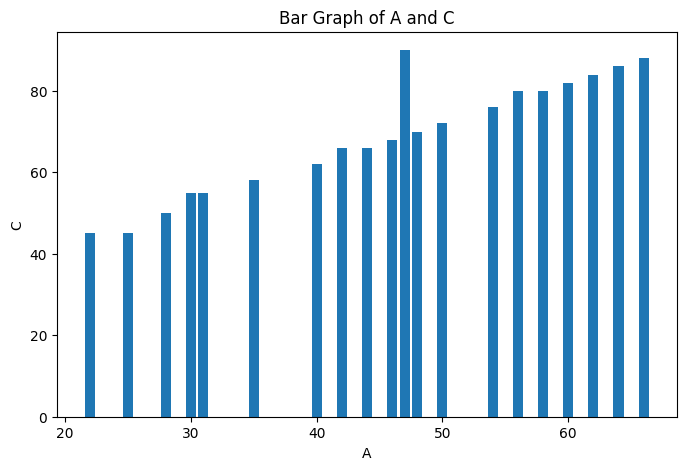

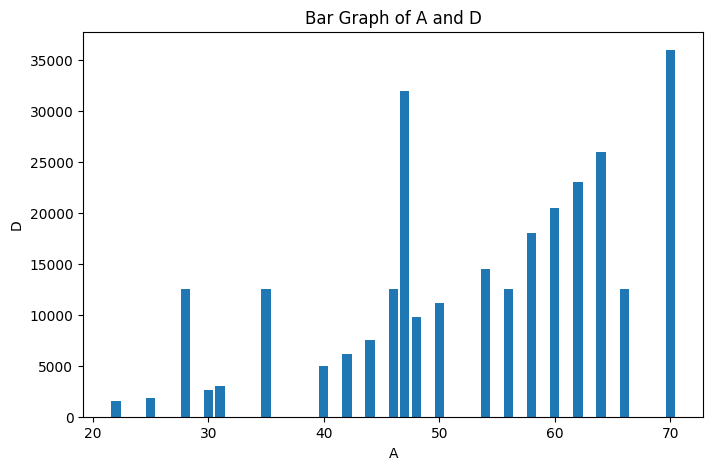

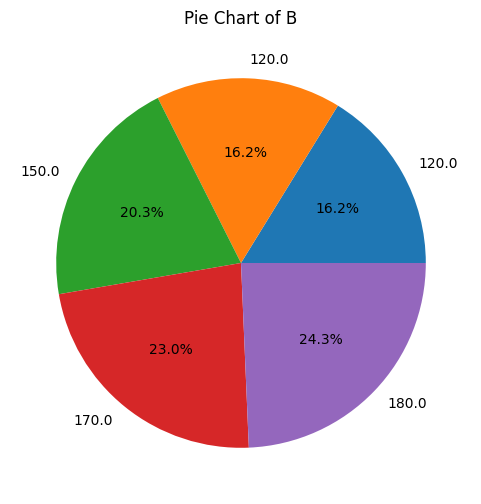

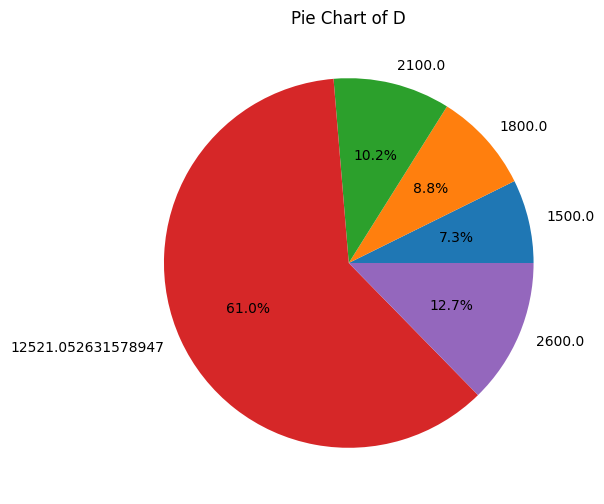

ValueError: Wedge sizes 'x' must be non negative values

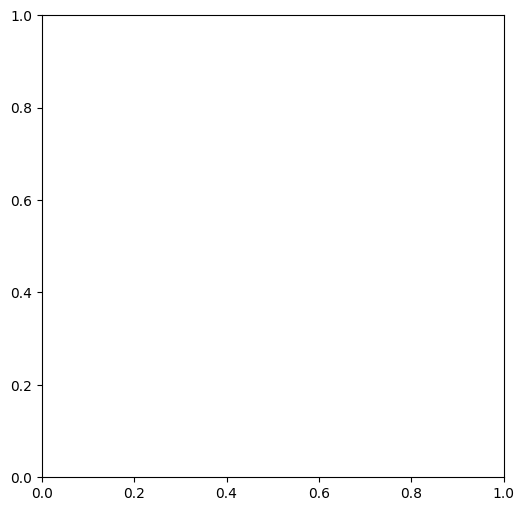

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

file_path = "preprocessing_dataset.csv"
df = pd.read_csv(file_path)

print("Missing Values:\n")
print(df.isnull().sum())

df = df.drop_duplicates()

print("\nNumber of duplicate rows removed:", df.duplicated().sum())

col1_median = df['A'].median()
df['A'].fillna(col1_median, inplace=True)
df['B'].fillna(method='ffill', inplace=True)
df['C'].fillna(method='bfill', inplace=True)
col4_mean = df['D'].mean()
df['D'].fillna(col4_mean, inplace=True)

scaler = StandardScaler()
df['E'].fillna(df['E'].mean(), inplace=True)
df['E'] = scaler.fit_transform(df[['E']])


print("\nCleaned Dataset:\n")
print(df.head())

plt.figure(figsize=(8,5))
plt.bar(df['A'], df['C'])
plt.xlabel('A')
plt.ylabel('C')
plt.title('Bar Graph of A and C')
plt.show()

plt.figure(figsize=(8,5))
plt.bar(df['A'], df['D'])
plt.xlabel('A')
plt.ylabel('D')
plt.title('Bar Graph of A and D')
plt.show()

plt.figure(figsize=(6,6))
plt.pie(df['B'].head(5), labels=df['B'].head(5), autopct='%1.1f%%')
plt.title('Pie Chart of B')
plt.show()

plt.figure(figsize=(6,6))
plt.pie(df['D'].head(5), labels=df['D'].head(5), autopct='%1.1f%%')
plt.title('Pie Chart of D')
plt.show()

plt.figure(figsize=(6,6))
plt.pie(df['E'].head(5), labels=df['E'].head(5), autopct='%1.1f%%')
plt.title('Pie Chart of E')
plt.show()